In [2]:
import numpy as np
import matplotlib.pyplot as plt

![](docs/img/kalman_filter_flowchart.png)

We will first implement a simple example of a radar tracking an aircraft. We are tracking range and velocity.
$
x=\begin{bmatrix}
r \\ v
\end{bmatrix}$

The initial measurement is: $z_0 = \begin{bmatrix}10000\\200\end{bmatrix}$

Let us assume that the standard deviation of the range measurement is 4m and the standard deviation of the velocity measurement is 0.5m/s.
Since variance is the square of the standard deviation, the squared measurement uncertainty (denoted by R) is
$
R_0 =
\begin{bmatrix}
\sigma²_r & \sigma²_{rv}\\
\sigma²_{vr} & \sigma²_v
\end{bmatrix}=
\begin{bmatrix}
16 & 0\\
0 & 0.25
\end{bmatrix}
$

The main diagonal elements contain the variances, and the off-diagonal elements are the covariances between measurements.

During initialization, the only information we have is a single measurement, thus we can use it as the initial estimate of the system state: 
$\hat{x}_{0,0}=z_0$.

The subscript 0,0 has the following meaning:
- The first index refers to the time of the system, which in this example is $t_0$
- The second index refers to the time at which the estimate was made, which is also $t_0$.



### PREDICT

- **State extrapolation equation**: 
$\hat{\boldsymbol{x}}_{n+1,n} = \boldsymbol{F}\hat{\boldsymbol{x}}_{n,n} + \boldsymbol{G}u_{n}\quad$
where $\begin{cases}u_n \text{ is an input variable}\\ G \text{ is an input transition matrix}\end{cases}$
- **Covariance extrapolation equation**:
$\boldsymbol{P}_{n+1,n} = \boldsymbol{F}\boldsymbol{P}_{n,n}\boldsymbol{F}^T + \boldsymbol{Q} \quad$
where $\begin{cases}Q \text{ is the process noise}\end{cases}$

#### Dynamics model

$dt=5s$. Therefore, $t_1=5s$

We assume a constant velocity dynamic model: $\begin{cases}v_1 = v_0 = v \\ r_1 = r_0 + v_0 dt \end{cases}$ 
$\qquad$ 
In matrix form (using the state transition matrix $F$): 
$$\hat{x}_{1,0} = F \hat{x}_{0,0} = \hat{\boldsymbol{x}}_{1,0} = \begin{bmatrix} \hat{r}_{1,0} \\ \hat{v}_{1,0} \end{bmatrix} = \begin{bmatrix} 1 & \Delta t \\ 0 & 1 \end{bmatrix} \begin{bmatrix} \hat{r}_{0,0} \\ \hat{v}_{0,0} \end{bmatrix} = \begin{bmatrix} 1 & 5 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} 10,000 \\ 200 \end{bmatrix} = \begin{bmatrix} 11,000 \\ 200 \end{bmatrix}$$

In this simple example, we assume there is no input, so $u_n=0$

#### Prediction covariance

**After predicting the next state, we should also ask: how precise is this prediction?**

The squared uncertainty of the current state estimate is represented by the covariance matrix:
$\boldsymbol{P}_{0,0} = \begin{bmatrix} 16 & 0 \\ 0 & 0.25 \end{bmatrix}$

However, the prediction covariance is not computed as: $\cancel{\boldsymbol{P}_{1,0} = \boldsymbol{F}\boldsymbol{P}_{0,0}}$
This is because $\boldsymbol{P}$ is a covariance matrix, and variances and covariances involve squared terms.  

$$\boldsymbol{P}_{1,0} = \boldsymbol{F}\boldsymbol{P}_{0,0}\boldsymbol{F}^T = \begin{bmatrix} 1 & 5 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} 16 & 0 \\ 0 & 0.25 \end{bmatrix} \begin{bmatrix} 1 & 0 \\ 5 & 1 \end{bmatrix} = \begin{bmatrix} 1 & 5 \\ 0 & 1 \end{bmatrix} \begin{bmatrix} 16 & 0 \\ 1.25 & 0.25 \end{bmatrix} = \begin{bmatrix} 22.25 & 1.25 \\ 1.25 & 0.25 \end{bmatrix}$$

The assumption of constant-velocity dynamics is not fully accurate. In reality, the aircraft's velocity can be affected by external and unknown factors, such as wind. As a result, the actual prediction uncertainty is higher than what the simple model predicts. **The unpredictable influences on our dynamics model are called process noise and are denoted by $Q$**.

The Q acknowledges that real-world objects don't follow linear equations perfectly and injects a bit of covariance to the prediction, but the underlying transition equation remains strictly linear.

**Adding noise to the prediction covariance**

Let us assume that the standard deviation of the random acceleration is $\sigma_a = 0.2 m/s^2$, thus, the random acceleration variance $\sigma_a^2 = 0.04 m^2/s^4$. 

For our example, the process noise matrix is given by:$\boldsymbol{Q} = \begin{bmatrix} \frac{\Delta t^4}{4} & \frac{\Delta t^3}{2} \\ \frac{\Delta t^3}{2} & \Delta t^2 \end{bmatrix} \sigma_a^2$

With $\Delta t = 5\text{s}$ and $\sigma_a^2 = 0.04\text{ m}^2/\text{s}^4$, this becomes:   $\boldsymbol{Q} = \begin{bmatrix} \frac{625}{4} & \frac{125}{2} \\ \frac{125}{2} & 25 \end{bmatrix} 0.04 = \begin{bmatrix} 6.25 & 2.5 \\ 2.5 & 1 \end{bmatrix}$

After adding the process noise, the squared uncertainty of our prediction is:
$\boldsymbol{P}_{1,0} = \boldsymbol{F}\boldsymbol{P}_{0,0}\boldsymbol{F}^T + \boldsymbol{Q} = \begin{bmatrix} 22.25 & 1.25 \\ 1.25 & 0.25 \end{bmatrix} + \begin{bmatrix} 6.25 & 2.5 \\ 2.5 & 1 \end{bmatrix} = \begin{bmatrix} 28.5 & 3.75 \\ 3.75 & 1.25 \end{bmatrix}$

### UPDATE

$$\boldsymbol{K}_{n} = \boldsymbol{P}_{n,n-1}\boldsymbol{H}^T \left( \boldsymbol{H}\boldsymbol{P}_{n,n-1}\boldsymbol{H}^T + \boldsymbol{R}_n \right)^{-1}$$

$$\hat{\boldsymbol{x}}_{n,n} = \hat{\boldsymbol{x}}_{n,n-1} + \boldsymbol{K}_n(\boldsymbol{z}_n - \boldsymbol{H}\hat{\boldsymbol{x}}_{n,n-1})$$

$$\boldsymbol{P}_{n,n} = (\boldsymbol{I} - \boldsymbol{K}_n\boldsymbol{H})\boldsymbol{P}_{n,n-1}$$

A second radar measurement comes in, $\boldsymbol{z}_1 = \begin{bmatrix} 11,020 \\ 202 \end{bmatrix}$, but this time the SNR is lower due to a noise spike. Let's assume that $\sigma_r=6m$ and $\sigma_v=1.5m/s$: $\boldsymbol{R}_1 = \begin{bmatrix} 36 & 0 \\ 0 & 2.25 \end{bmatrix}$

#### Prediction covariance vs measurement covariance (P vs R)

We can immediately see that $\boldsymbol{R}_1 = \begin{bmatrix} 36 & 0 \\ 0 & 2.25 \end{bmatrix}$ is higher than $\boldsymbol{P}_{1,0} = \begin{bmatrix} 28.5 & 3.75 \\ 3.75 & 1.25 \end{bmatrix}$.
Thus, measurement covariance is higher than prediction covariance. 

**The idea is to combine measurement and prediction to minimize the overall uncertainty of the estimate**

This is done via the Kalman gain. We want to find a weight that allows combining measurement and prediction: $\hat{x}_{1,1} = K_1 z_1 + (1 - K_1)\hat{x}_{1,0} = \hat{\boldsymbol{x}}_{1,0} + \boldsymbol{K}_1 (\boldsymbol{z}_1 - \hat{\boldsymbol{x}}_{1,0}), \quad 0 \le K_1 \le 1$

#### Observation Matrix

In our example, both the system state and the measurement are vectors that represent the same physical quantities (range and velocity). Therefore, we can directly subtract 
$\hat{x}_{1,0}$ from $z_1$

However, this is not always the case. In general, the measurement and the system state may belong to different physical domains. For example, a digital thermometer measures an electrical signal, while the system state is the temperature. For this reason, the predicted state must first be transformed into the measurement domain: $\boldsymbol{H}\hat{\boldsymbol{x}}_{1,0}$

In our example, the observation matrix is the identity: $\boldsymbol{H} = \begin{bmatrix} 1 & 0 \\ 0 & 1 \end{bmatrix} = \boldsymbol{I}$

The state update ecuation becomes:
$\hat{\boldsymbol{x}}_{1,1} = \hat{\boldsymbol{x}}_{1,0} + \boldsymbol{K}_1(\boldsymbol{z}_1 - \boldsymbol{H}\hat{\boldsymbol{x}}_{1,0})$

#### Kalman Gain
Obtain a weight ($0 \le K_1 \le 1$) that combines the measurement and prediction covariances. This gives a single weight that tells us if we should trust the measurement or the prediction more.

$\boldsymbol{K}_{n} = \boldsymbol{P}_{n,n-1}\boldsymbol{H}^T \left( \boldsymbol{H}\boldsymbol{P}_{n,n-1}\boldsymbol{H}^T + \boldsymbol{R}_n \right)^{-1}$

#### Estimate covariance

The estimate (posterior) covariance ($P_{k\vert{}k}$) is a mathematical blend of the prediction (prior) covariance ($P_{k\vert{}k-1}$) and the measurement covariance ($R$), weighted by the Kalman Gain ($K$).

$$\boldsymbol{P}_{n,n} = (\boldsymbol{I} - \boldsymbol{K}_n\boldsymbol{H})\boldsymbol{P}_{n,n-1}$$

## Implementing the aircraft example

1. Simulate an aircraft Ground truth trajectory (range $r$ and radial velocity $v$)
2. Add gaussian noise (governed by mean and stdev) to them to obtain measurement and standard deviation.
3. Simulate some steps

For the linear Kalman filter, our state variables are directly r and v, which are also the measurement unit of the radar. What I mean is that there is no conversion between measurements and state, since both are the same type of variable. After this we will implement the EKF, that will allow us to track $(x, y, v_x, v_y)$ from $R, V_r$. 

Because the LKF does not track positions, it makes no sense to generate dummy position data. This happens because there are multiple trajectories that can be created for the same $v$ and $r$ data.
We will directly generate dummy range and radial velocity data of a plane moving.

#### Modeling Q
We will use the continuous white noise acceleration model (CWNA). 
Assuming a random acceleration variance $\sigma_a^2$ (representing the magnitude of unexpected accelerations), the process noise covariance matrix over a time step $\Delta t$ is integrated as:$$Q = \sigma_a^2 \begin{bmatrix} \frac{\Delta t^3}{3} & \frac{\Delta t^2}{2} \\ \frac{\Delta t^2}{2} & \Delta t \end{bmatrix}$$

In [3]:
dt = 0.1
total_time = 10.0
t = np.arange(0, total_time, dt)
N = len(t)

r0 = 1000.0 # initial position at 1000m
v_0 = -15.0 # constant radial speed (m/s, moving closer to the radar)

gt_r = r0 + v_0 * t
gt_v = v_0 * np.ones(N)

# we assume fixed stdev for r and v
# for a real radar, this could be specific to each measurement (depending on SNR for example). So R could change for each measurement.
sigma_r = 10
sigma_v = .5

measurements_r = gt_r + np.random.normal(0, sigma_r, N)
measurements_v = gt_v + np.random.normal(0, sigma_v, N)

# Q modeled according to CWNA model
# An acceleration of v_0 of 0.05 is modeled into the KF as a possiblity due to unpredictable environmental influences such as wind
sigma_a = 0.05 # random acceleration variance. 

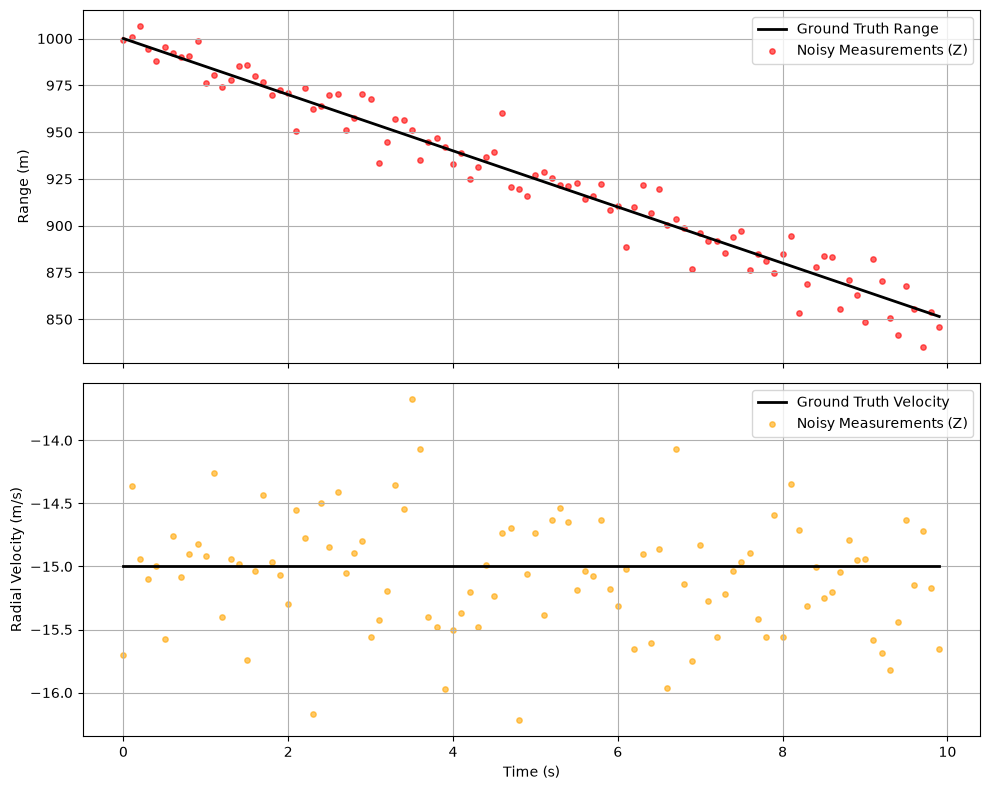

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(t, gt_r, 'k-', label='Ground Truth Range', lw=2)
ax1.scatter(t, measurements_r, color='red', s=15, alpha=0.6, label='Noisy Measurements (Z)')
ax1.set_ylabel('Range (m)')
ax1.grid(True)
ax1.legend(loc='upper right')

ax2.plot(t, gt_v, 'k-', label='Ground Truth Velocity', lw=2)
ax2.scatter(t, measurements_v, color='orange', s=15, alpha=0.6, label='Noisy Measurements (Z)')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Radial Velocity (m/s)')
ax2.grid(True)
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

In [5]:
class LKF:
    def __init__(self):
        # state
        self.x = np.array([[r0], [v_0]])

        self.F = np.array([[1, dt], [0, 1]]) # state transition matrix
        self.P = np.array([[sigma_r**2, 0], [0, sigma_v**2]]) # prediction covariance
        self.Q = np.array([[dt**3/3, dt**2/2], [dt**2/2, dt]]) * sigma_a # process noise matrix
        
        self.H = np.identity(2) # observation matrix
        self.R = np.array([[sigma_r**2, 0], [0, sigma_v**2]]) # measurement covariance

    def predict(self):
        # x_n+1,n = F x_n,n + G u_n
        # No controls, so G is skipped
        self.x = self.F @ self.x

        # P_n+1,n = F P_n,n F^T + Q 
        self.P = self.F @ self.P @ self.F.T + self.Q

    def update(self, z: np.ndarray):
        # K_n = P_n,n-1 H^T (H P_n,n-1 H^T + R_n)^-1
        K = self.P @ self.H.T @ np.linalg.inv(self.H @ self.P @ self.H.T + self.R)

        # x_n,n = x_n,n-1 + K (z - H x_n,n-1)
        diff = z - self.H @ self.x
        self.x = self.x + K @ diff

        # P_n,n = (I - K_n H) P_n,n-1
        self.P = (np.identity(2) - K @ self.H) @ self.P

        return self.x

In [6]:
kf = LKF()

kf_r = np.zeros(N)
kf_v = np.zeros(N)

for i in range(N):
    kf.predict()
    x = kf.update(np.array([[measurements_r[i]], [measurements_v[i]]]))

    r, v = x[0,0], x[1,0]
    kf_r[i] = r
    kf_v[i] = v

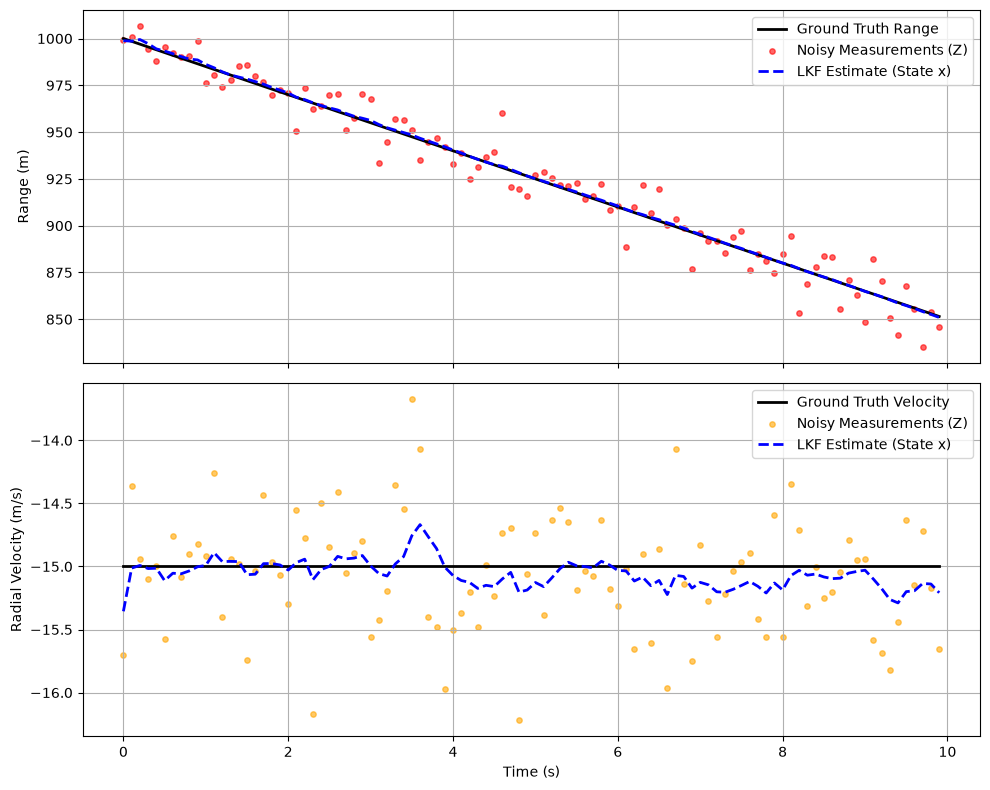

In [7]:
def plot_lkf(t, gt_r, gt_v, kf_r, kf_v):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

    ax1.plot(t, gt_r, 'k-', label='Ground Truth Range', lw=2)
    ax1.scatter(t, measurements_r, color='red', s=15, alpha=0.6, label='Noisy Measurements (Z)')
    ax1.plot(t, kf_r, 'b--', label='LKF Estimate (State x)', lw=2)
    ax1.set_ylabel('Range (m)')
    ax1.grid(True)
    ax1.legend(loc='upper right')

    ax2.plot(t, gt_v, 'k-', label='Ground Truth Velocity', lw=2)
    ax2.scatter(t, measurements_v, color='orange', s=15, alpha=0.6, label='Noisy Measurements (Z)')
    ax2.plot(t, kf_v, 'b--', label='LKF Estimate (State x)', lw=2)
    ax2.set_xlabel('Time (s)')
    ax2.set_ylabel('Radial Velocity (m/s)')
    ax2.grid(True)
    ax2.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

plot_lkf(t, gt_r, gt_v, kf_r, kf_v)

### Adding measurement uncertainty decay
As we said, sigma_r and sigma_v should probably be specific to each measurement. So to make the problem more realistic, we can decay the uncertainty of measurements as the aircraft gets closer.



In [8]:
dt = 0.1
total_time = 10.0
t = np.arange(0, total_time, dt)
N = len(t)

# Motion along a fixed angle (e.g., 45 degrees / pi/4 radians)
theta = np.pi / 4  
r0 = 1000.0 # initial position at 1000m
v_0 = -15.0 # constant radial speed (m/s, moving closer to the radar)

gt_r = r0 + v_0 * t
gt_v = v_0 * np.ones(N)

# Q modeled according to CWNA model
# An acceleration of v_0 of 0.05 is modeled into the KF as a possiblity due to unpredictable environmental influences such as wind
sigma_a = 0.05 # random acceleration variance. 

In [9]:
# one measurement uncertainty per measurement
# uncertainty decreases linearlywith the following formulas (invented by me, not physically relevant): 
#   sigma_r = r * 0.03 + 8
#   sigma_v = r * 0.0005 + 0.4

measurements_r = np.zeros(N)
measurements_v = np.zeros(N)
sigma_r = np.zeros(N)
sigma_v = np.zeros(N)

for i in range(N):
    sigma_r_i = gt_r[i]*0.03+8
    sigma_v_i = gt_r[i]*0.0005+0.4

    sigma_r[i] = sigma_r_i
    sigma_v[i] = sigma_v_i
    measurements_r[i] = gt_r[i] + np.random.normal(0, sigma_r_i)
    measurements_v[i] = gt_v[i] + np.random.normal(0, sigma_v_i)

In [10]:
class LKF:
    def __init__(self):
        # state
        self.x = np.array([[r0], [v_0]])

        self.F = np.array([[1, dt], [0, 1]]) # state transition matrix
        self.P = np.diag([sigma_r[0]**2, sigma_v[0]**2]) # prediction covariance
        self.Q = np.array([[dt**3/3, dt**2/2], [dt**2/2, dt]]) * sigma_a # process noise matrix
        
        self.H = np.identity(2) # observation matrix

    def predict(self):
        # x_n+1,n = F x_n,n + G u_n
        # No controls, so G is skipped
        self.x = self.F @ self.x

        # P_n+1,n = F P_n,n F^T + Q 
        self.P = self.F @ self.P @ self.F.T + self.Q

    def update(self, z: np.ndarray, i: int):
        self.R = np.diag([sigma_r[i]**2, sigma_v[i]**2]) # measurement covariance

        # K_n = P_n,n-1 H^T (H P_n,n-1 H^T + R_n)^-1
        K = self.P @ self.H.T @ np.linalg.inv(self.H @ self.P @ self.H.T + self.R)

        # x_n,n = x_n,n-1 + K (z - H x_n,n-1)
        diff = z - self.H @ self.x
        self.x = self.x + K @ diff

        # P_n,n = (I - K_n H) P_n,n-1
        self.P = (np.identity(2) - K @ self.H) @ self.P

        return self.x

In [11]:
kf = LKF()

kf_r = np.zeros(N)
kf_v = np.zeros(N)

for i in range(N):
    kf.predict()
    x = kf.update(np.array([[measurements_r[i]], [measurements_v[i]]]), i)

    r, v = x[0,0], x[1,0]
    kf_r[i] = r
    kf_v[i] = v

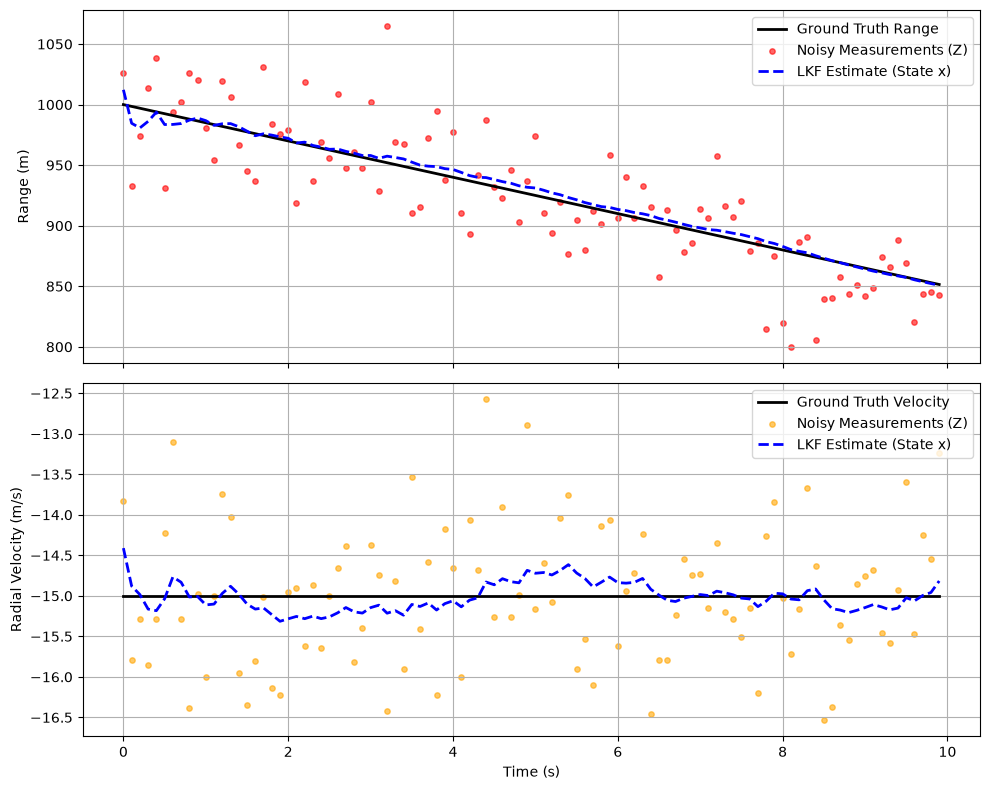

In [12]:
plot_lkf(t, gt_r, gt_v, kf_r, kf_v)

### What if the constant radial velocity assumption does not hold ?

For now, the underlying physics are linear. I want to analyze what happens when the linearity assumption does not hold.

My concern before testing this is that I can't truly know if I am testing model mismatch or the KF breaking down due to non-linearity in the underlying physics. I guess the only way to truly be sure would be to test a linear physics model that does not match the KF, but we will leave it for later.

The physics equations for generating ground truth will now be:

$$r(t) = r_0 + v_0 t + \frac{1}{2} a t^2$$

$$v(t) = v_0 + a t$$

In [21]:
dt = 0.1
total_time = 20.0
t = np.arange(0, total_time, dt)
N = len(t)
 
r0 = 1000.0 # initial position at 1000m
v_0 = -15.0 # radial speed (m/s, moving closer to the radar)

a = 2.0
gt_r = r0 + v_0 * t + .5 * a * t*t
gt_v = v_0 + a * t

# Q modeled according to CWNA model
# An acceleration of v_radial of 0.05 is modeled into the KF as a possiblity due to unpredictable environmental influences such as wind
sigma_a = 0.05 # random acceleration variance.

In [22]:
# one measurement uncertainty per measurement
# uncertainty decreases linearlywith the following formulas (invented by me, not physically relevant): 
#   sigma_r = r * 0.03 + 8
#   sigma_v = r * 0.0005 + 0.4

measurements_r = np.zeros(N)
measurements_v = np.zeros(N)
sigma_r = np.zeros(N)
sigma_v = np.zeros(N)

for i in range(N):
    sigma_r_i = gt_r[i]*0.03+8
    sigma_v_i = gt_r[i]*0.0005+0.4

    sigma_r[i] = sigma_r_i
    sigma_v[i] = sigma_v_i
    measurements_r[i] = gt_r[i] + np.random.normal(0, sigma_r_i)
    measurements_v[i] = gt_v[i] + np.random.normal(0, sigma_v_i)

In [23]:
kf = LKF()

kf_r = np.zeros(N)
kf_v = np.zeros(N)

for i in range(N):
    kf.predict()
    x = kf.update(np.array([[measurements_r[i]], [measurements_v[i]]]), i)

    r, v = x[0,0], x[1,0]
    kf_r[i] = r
    kf_v[i] = v

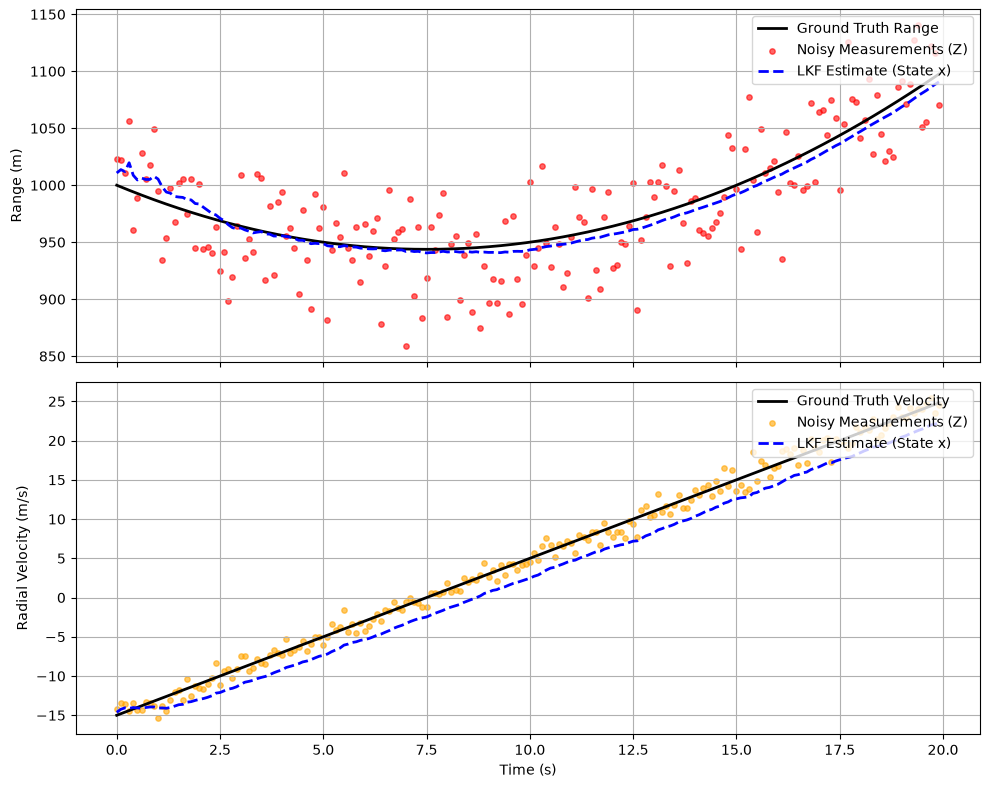

In [24]:
plot_lkf(t, gt_r, gt_v, kf_r, kf_v)

We can see how the model lags a bit behind for both the range and the velocity states. The measurements keep pushing the velocity upwards while the model thinks the velocity will stay constant. 

Gemini has pointed out that this physics model could actually be modeled by an LKF, even though the physics seem non-linear. I want to test it out to see if the results are better than above. If we include the acceleration as a state, we can use this state transition equations:

$$r(t) = r_0 + v_0 t + \frac{1}{2} a t^2$$

$$v(t) = v_0 + a t$$

$$a(t) = a$$

Because every single term is just a constant multiplied by a state to the first power, this equation is strictly linear in terms of the states.

We also have to modify Q. We will use CWNJ (Continuous White Noise Jerk). CWNA (Continuous White Noise Acceleration) assumed white noise acceleration, whilst CWNJ assumes white white noise jerk (rate of change of acceleration).

$$Q = \sigma_j^2 \begin{bmatrix} \frac{\Delta t^5}{20} & \frac{\Delta t^4}{8} & \frac{\Delta t^3}{6} \\  \frac{\Delta t^4}{8} & \frac{\Delta t^3}{3} & \frac{\Delta t^2}{2} \\  \frac{\Delta t^3}{6} & \frac{\Delta t^2}{2} & \Delta t \end{bmatrix}$$

Even though $a$ is a new state, the sensor only measures $r$ and $v$, so the $H$ only maps those columns:

$$H = \begin{bmatrix} 1 & 0 & 0 \\  0 & 1 & 0 \end{bmatrix}$$

In [28]:
a_0 = 2
sigma_j = 1.0

In [31]:
class ConstantAccelLKF:
    def __init__(self):
        # state
        self.x = np.array([[r0], [v_0], [a_0]])

        self.F = np.array([[1, dt, 0.5*dt*dt], [0, 1, dt], [0, 0, 1]]) # state transition matrix
        self.P = np.diag([sigma_r[0]**2, sigma_v[0]**2, 1]) # prediction covariance
        self.Q = np.array([[dt**5/20, dt**4/8, dt**3/6], [dt**4/8, dt**3/3, dt**2/2], [dt**3/6, dt**2/2, dt]]) * sigma_j # process noise matrix
        
        self.H = np.array([[1, 0, 0], [0, 1, 0]]) # observation matrix

    def predict(self):
        # x_n+1,n = F x_n,n + G u_n
        # No controls, so G is skipped
        self.x = self.F @ self.x

        # P_n+1,n = F P_n,n F^T + Q 
        self.P = self.F @ self.P @ self.F.T + self.Q

    def update(self, z: np.ndarray, i: int):
        self.R = np.diag([sigma_r[i]**2, sigma_v[i]**2]) # measurement covariance

        # K_n = P_n,n-1 H^T (H P_n,n-1 H^T + R_n)^-1
        K = self.P @ self.H.T @ np.linalg.inv(self.H @ self.P @ self.H.T + self.R)

        # x_n,n = x_n,n-1 + K (z - H x_n,n-1)
        diff = z - self.H @ self.x
        self.x = self.x + K @ diff

        # P_n,n = (I - K_n H) P_n,n-1
        self.P = (np.identity(3) - K @ self.H) @ self.P

        return self.x

In [34]:
kf = ConstantAccelLKF()

kf_r = np.zeros(N)
kf_v = np.zeros(N)

for i in range(N):
    kf.predict()
    x = kf.update(np.array([[measurements_r[i]], [measurements_v[i]]]), i)

    r, v = x[0,0], x[1,0]
    kf_r[i] = r
    kf_v[i] = v

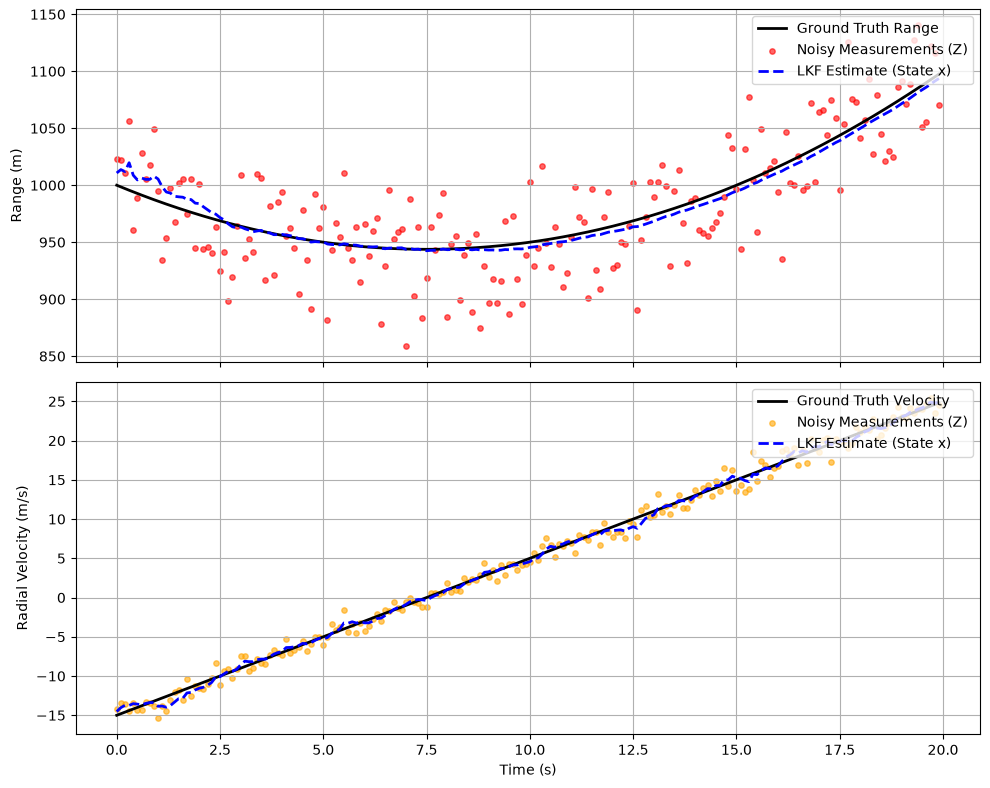

In [35]:
plot_lkf(t, gt_r, gt_v, kf_r, kf_v)

The estimations are much accurate now, especially the velocity one.